# 4.1 PCA completo

**CRISP-DM fase 3 Â· Data Preparation Â· PCA diagnostico.**
Cuaderno satelite de `3.0_transformacion.ipynb`: profundiza en los componentes principales de las variables numericas escaladas, sin exportar una matriz reducida.
Muestra utilizada: `min(50000, n)` filas por version.


In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
if ROOT.name == "refactor":
    ROOT = ROOT.parent.parent
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif ROOT.name != "MineriaProtect":
    for p in [ROOT] + list(ROOT.parents):
        if p.name == "MineriaProtect":
            ROOT = p
            break
sys.path.insert(0, str(ROOT))

from scripts.ScriptsCsv.Transformacion.column_profile import profile_columns
from scripts.ScriptsCsv.Transformacion.config import VERSION_CON, VERSION_SIN, processed_path
from scripts.ScriptsCsv.Transformacion.date_features import add_date_ordinals, add_job_order, add_start_year
from scripts.ScriptsCsv.Transformacion.encoding import derive_skill_presence, ordinal_from_mapping
from scripts.ScriptsCsv.Transformacion.pca_diagnostic import components_for_threshold, run_pca, top_loadings
from scripts.ScriptsCsv.Transformacion.scaling import fit_transform_full

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
SAMPLE_SIZE = 50000


In [2]:
UNIV_ORDER = {"No reportado": 0, "Secondary school": 1, "Bachelor": 2, "Master": 3, "PhD": 4}
SCALING_PLAN = {
    "start_ord": "robust", "end_ord": "robust", "dur_q": "robust",
    "n_skills_essential": "robust", "n_skills_competence": "robust",
    "n_skills_knowledge": "robust", "n_skills_sin_tipo": "robust",
    "veces_ese_oficio": "robust", "start_year": "robust",
    "job_order": "robust", "univ_ord": "minmax",
}
def read_version(version):
    path = processed_path(version)
    df = pd.read_csv(path, dtype=str, encoding="utf-8", keep_default_na=False, na_values=[""])
    occupation = df["occupation_code"].fillna("").astype(str).str.strip()
    fusion = occupation.eq("") & df["matched_code"].astype(str).str.strip().ne("unknown")
    occupation.loc[fusion] = df.loc[fusion, "matched_code"].astype(str)
    df["occupation_code"] = occupation.replace("", pd.NA).fillna("unknown")
    df = add_date_ordinals(df, "start_date", "end_date")
    df = add_start_year(df)
    df = add_job_order(df, "resume_id", "start_ord")
    for col in ["n_skills_essential", "n_skills_competence", "n_skills_knowledge", "n_skills_sin_tipo", "veces_ese_oficio"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df = derive_skill_presence(df, ["skills", "knowledge", "sin_tipo"], ["tiene_skills", "tiene_knowledge", "tiene_sin_tipo"])
    df = ordinal_from_mapping(df, "university_level", UNIV_ORDER, "univ_ord")
    return df

df_con = read_version(VERSION_CON)
df_sin = read_version(VERSION_SIN)
work_con = df_con[df_con.n_skills_essential.notna()].copy().reset_index(drop=True)
work_sin = df_sin[df_sin.n_skills_essential.notna()].copy().reset_index(drop=True)
print("Universo con/sin:", work_con.shape, work_sin.shape)


Universo con/sin: (348263, 32) (348263, 32)


In [3]:
sample_n = lambda n, size: min(size, len(n))
sample_con = work_con[sorted(set(SCALING_PLAN))].sample(n=sample_n(work_con, SAMPLE_SIZE), random_state=RANDOM_SEED)
sample_sin = work_sin[sorted(set(SCALING_PLAN))].sample(n=sample_n(work_sin, SAMPLE_SIZE), random_state=RANDOM_SEED)
_, scaled_con = fit_transform_full(sample_con, SCALING_PLAN)
_, scaled_sin = fit_transform_full(sample_sin, SCALING_PLAN)

var_con, load_con, _ = run_pca(scaled_con, n_components=10)
var_sin, load_sin, _ = run_pca(scaled_sin, n_components=10)
print("Componentes 80/90 (con):", components_for_threshold(var_con, 0.80), components_for_threshold(var_con, 0.90))
print("Componentes 80/90 (sin):", components_for_threshold(var_sin, 0.80), components_for_threshold(var_sin, 0.90))
display(var_con)
display(var_sin)


Componentes 80/90 (con): 4 5
Componentes 80/90 (sin): 3 5


,component,explained_variance_ratio,cumulative_variance
0,PC1,0.324269,0.324269
1,PC2,0.222065,0.546334
2,PC3,0.207168,0.753502
3,PC4,0.123132,0.876634
4,PC5,0.063763,0.940397
5,PC6,0.053963,0.994360
6,PC7,0.004539,0.998899
7,PC8,0.001072,0.999970
8,PC9,0.000030,1.000000
9,PC10,0.000000,1.000000


,component,explained_variance_ratio,cumulative_variance
0,PC1,0.394570,0.394570
1,PC2,0.260789,0.655358
2,PC3,0.146502,0.801860
3,PC4,0.087832,0.889692
4,PC5,0.063737,0.953430
5,PC6,0.039314,0.992744
6,PC7,0.005471,0.998214
7,PC8,0.001304,0.999518
8,PC9,0.000446,0.999964
9,PC10,0.000036,1.000000



Top loadings PC1 (con):


,abs_loading,signed_loading
dur_q_rob,0.841411,0.841411
start_ord_rob,0.342224,-0.342224
start_year_rob,0.340785,-0.340785
job_order_rob,0.173067,-0.173067
end_ord_rob,0.095767,-0.095767
veces_ese_oficio_rob,0.095639,-0.095639



Top loadings PC1 (sin):


,abs_loading,signed_loading
dur_q_rob,0.851195,0.851195
start_ord_rob,0.343366,-0.343366
start_year_rob,0.341929,-0.341929
job_order_rob,0.168270,-0.168270
end_ord_rob,0.093689,-0.093689
veces_ese_oficio_rob,0.048247,-0.048247



Top loadings PC2 (con):


,abs_loading,signed_loading
n_skills_essential_rob,0.524132,0.524132
n_skills_competence_rob,0.491263,0.491263
end_ord_rob,0.370933,0.370933
dur_q_rob,0.360125,0.360125
n_skills_knowledge_rob,0.281599,0.281599
start_ord_rob,0.219680,0.219680


... (2 outputs left out)


Top loadings PC3 (con):


,abs_loading,signed_loading
end_ord_rob,0.501592,0.501592
n_skills_essential_rob,0.410590,-0.410590
n_skills_competence_rob,0.380579,-0.380579
start_ord_rob,0.354692,0.354692
start_year_rob,0.354439,0.354439
dur_q_rob,0.298366,0.298366



Top loadings PC3 (sin):


,abs_loading,signed_loading
n_skills_essential_rob,0.671483,0.671483
n_skills_competence_rob,0.662750,0.662750
n_skills_knowledge_rob,0.291385,0.291385
veces_ese_oficio_rob,0.123835,0.123835
job_order_rob,0.052300,0.052300
end_ord_rob,0.047406,-0.047406


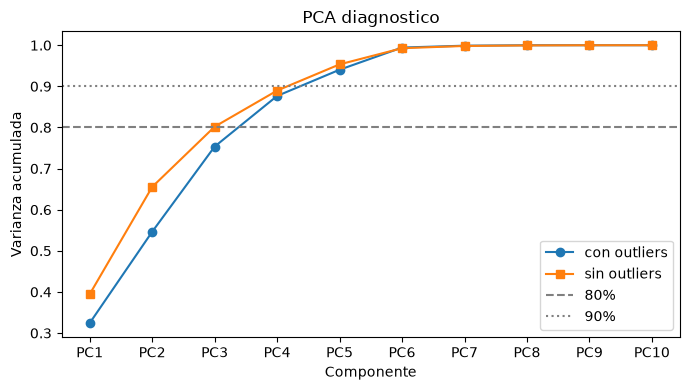

In [4]:
for pc in ["PC1", "PC2", "PC3"]:
    print(f"\nTop loadings {pc} (con):")
    display(top_loadings(load_con, pc, n=6))
    print(f"\nTop loadings {pc} (sin):")
    display(top_loadings(load_sin, pc, n=6))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(var_con["component"], var_con["cumulative_variance"], marker="o", label="con outliers")
ax.plot(var_sin["component"], var_sin["cumulative_variance"], marker="s", label="sin outliers")
ax.axhline(0.8, linestyle="--", color="gray", label="80%")
ax.axhline(0.9, linestyle=":", color="gray", label="90%")
ax.set_ylabel("Varianza acumulada")
ax.set_xlabel("Componente")
ax.set_title("PCA diagnostico")
ax.legend()
plt.tight_layout()
plt.show()


## Lectura del diagnostico

El PCA se usa solo como diagnostico. Si `start_ord`, `end_ord` y `dur_q` dominan los primeros componentes, eso indica redundancia lineal (dur_q = end_ord - start_ord + 1), no un enriquecimiento util. Si las columnas de skills pesan por separado, hay informacion propia de complejidad del oficio. Ganar varianza acumulada rapida no significa necesariamente que las variables sean intercambiables para el negocio: los loadings deben leerse junto con la pregunta de transiciones.
